In [6]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans



In [7]:
# Step 1: Load and inspect the dataset
df = pd.read_csv("Mall_Customers.csv")
print("Dataset shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
features = ["Annual Income (k$)", "Spending Score (1-100)"]
print("\nSelected feature summary:\n", df[features].describe())


Dataset shape: (200, 5)

Missing values:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Selected feature summary:
        Annual Income (k$)  Spending Score (1-100)
count          200.000000              200.000000
mean            60.560000               50.200000
std             26.264721               25.823522
min             15.000000                1.000000
25%             41.500000               34.750000
50%             61.500000               50.000000
75%             78.000000               73.000000
max            137.000000               99.000000


In [8]:

# Step 2: Select features
X = df[features].copy()



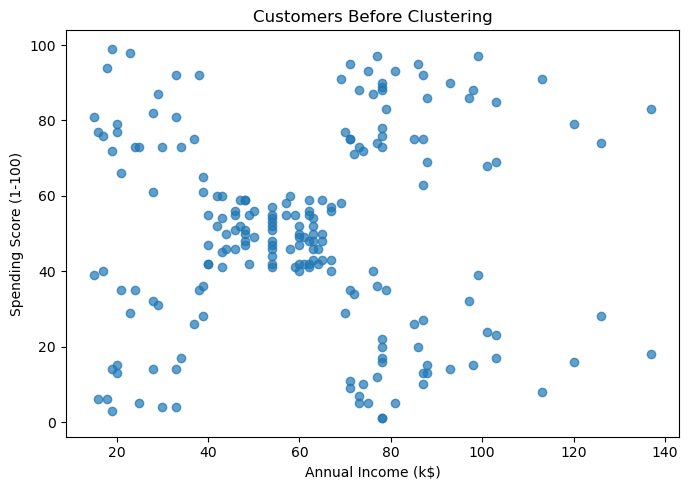

In [9]:
# Step 3: Visualize original data
plt.figure(figsize=(7, 5))
plt.scatter(X[features[0]], X[features[1]], alpha=0.7)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customers Before Clustering")
plt.tight_layout()
plt.savefig("q25_original_customers.png", dpi=160)
plt.show()


In [10]:

# Step 4: Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)



c:\Users\PC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\PC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\PC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\PC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, 

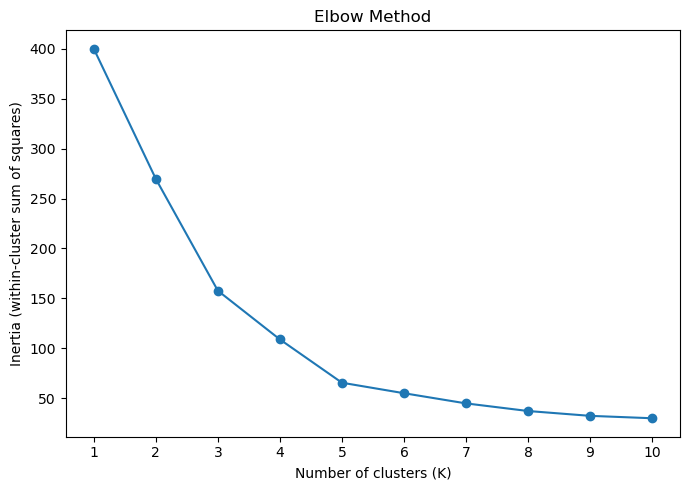

In [11]:
# Step 5: Apply the Elbow Method
inertias = []
k_values = range(1, 11)
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.title("Elbow Method")
plt.tight_layout()
plt.savefig("q25_elbow_method.png", dpi=160)
plt.show()


In [12]:

# Step 6: Train K-Means with K=5
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)
centroids = scaler.inverse_transform(kmeans.cluster_centers_)


c:\Users\PC\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [13]:

# Step 7: Print cluster information
print("\nCluster counts:\n", df["Cluster"].value_counts().sort_index())
print("\nCluster averages:\n", df.groupby("Cluster")[features].mean().round(2))
print("\nCentroids in original units:\n", pd.DataFrame(centroids, columns=features).round(2))
print("\nFinal inertia:", round(kmeans.inertia_, 2))



Cluster counts:
 Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Cluster averages:
          Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     55.30                   49.52
1                     86.54                   82.13
2                     25.73                   79.36
3                     88.20                   17.11
4                     26.30                   20.91

Centroids in original units:
    Annual Income (k$)  Spending Score (1-100)
0               55.30                   49.52
1               86.54                   82.13
2               25.73                   79.36
3               88.20                   17.11
4               26.30                   20.91

Final inertia: 65.57


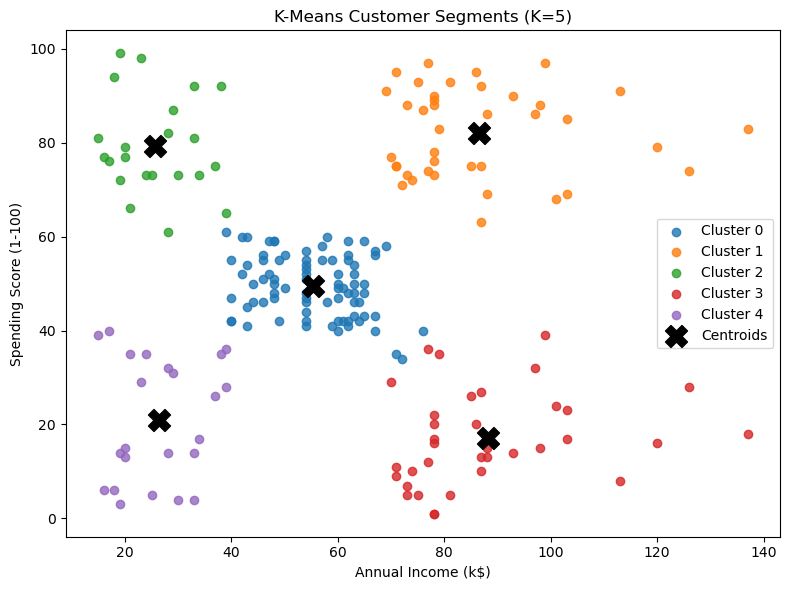

In [14]:

# Step 8: Visualize clusters
plt.figure(figsize=(8, 6))
for cluster in sorted(df["Cluster"].unique()):
    group = df[df["Cluster"] == cluster]
    plt.scatter(group[features[0]], group[features[1]], label=f"Cluster {cluster}", alpha=0.8)

plt.scatter(centroids[:, 0], centroids[:, 1], marker="X", s=250, c="black", label="Centroids")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means Customer Segments (K=5)")
plt.legend()
plt.tight_layout()
plt.savefig("q25_customer_clusters.png", dpi=160)
plt.show()
